# Household flood adaptation in Charleston

### A walkthrough of the coupled FloodAdapt and DYNAMO-M model

This notebook follows about 58,000 households in Charleston through 30 years of rising sea level, from 2020 to 2049. Each year some of them are flooded. Each household then decides whether to protect its home, buy insurance or do nothing.

**What the model combines**

* **FloodAdapt supplies the hazard.** A precomputed table gives the damage to every building for 207 flood events, five sea levels and two strategies: no measures, and dry floodproofing of every building to 2 ft.
* **DYNAMO-M supplies the behaviour.** Households compare the expected utility of their options, using their own risk perception, income and wealth.
* **A Monte-Carlo engine ties them together.** It draws the floods for every year and repeats the 30 years five times with different flood histories.

**The runs**

| Run | How households decide | Insurance on offer |
|---|---|---|
| 1 Uniform rule | a fixed trigger: floodproof once a single year's damage exceeds 30 % of the building value | none |
| 2 Coupled | DYNAMO-M expected utility | none |
| 3 Community | DYNAMO-M | one flat premium for everyone |
| 4 Risk-based | DYNAMO-M | each household pays its own expected loss |
| 5 to 7 | DYNAMO-M | Runs 3 and 4 with a public subsidy of 60 % or 90 % |

All runs see exactly the same floods, so any difference between them comes from the decisions alone.

**How to read it.** Each results section ends with *What we see*. The code cells are short because the work happens in the `floodadapt_abm` package. Every scenario, the alternative income methods, the verification checks and the background are in [3_coupled_abm_full_analysis.ipynb](3_coupled_abm_full_analysis.ipynb).

The full run takes about 30 minutes on the real table. Set `USE_REAL_TABLE = False` below for a quick check on a small synthetic table.

## 1. Setup

The settings below are the model defaults. Floods follow a Poisson draw, so a year can bring no flood, one flood or several. Events that occur more than once a year on average are tidal nuisance floods and are left out.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the examples' table loader (real Charleston table or a synthetic one).
_REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(_REPO / "examples_engine"))
from _shared import load_dataset  # noqa: E402

from floodadapt_abm import (  # noqa: E402
    CouplingConfig, SimulationEngine, ThresholdRule,
    preferred_decision_rule, run_mesa_native_full,
    analysis, plotting,
)
from floodadapt_abm.income_utils import percentiles_from_value_proxy  # noqa: E402

START_YEAR, N_YEARS = 2020, 30
NO_SEQ = 5              # Monte-Carlo sequences (flood histories)
SEED = 42
USE_REAL_TABLE = True

ds, source = load_dataset(prefer_real=USE_REAL_TABLE)
config = CouplingConfig(random_seed=SEED)          # Poisson draw by default
if "real" in source:
    config.decision.nuisance_freq_threshold = 1.0  # drop sub-annual tidal events

# Sea level rises linearly across the table's range (0 to 2 ft) over 30 years.
slr_values = np.linspace(float(ds.slr.min()), float(ds.slr.max()), N_YEARS)
years = START_YEAR + np.arange(N_YEARS)

# One colour per run in every figure. Dashed lines mark risk-based pricing.
RUN1, RUN2 = "1 Uniform rule", "2 Coupled"
RUN3, RUN4 = "3 Community", "4 Risk-based"
RUN5, RUN6, RUN7 = "5 Community + 60%", "6 Risk-based + 60%", "7 Risk-based + 90%"
STYLES = {
    RUN1: ("#7f7f7f", "-"),
    RUN2: ("C0", "-"),
    RUN3: ("C1", "-"),
    RUN4: ("C2", "--"),
    RUN5: ("C3", "-"),
    RUN6: ("C4", "--"),
    RUN7: ("C5", "--"),
}

print(f"Lookup table : {source}")
print(f"Households   : {int((np.char.find(np.asarray(ds['object_id'].attrs['primary_object_type'], dtype=str), 'RES') >= 0).sum()):,}")
print(f"Sea level    : {slr_values[0]:.1f} to {slr_values[-1]:.1f} ft over {N_YEARS} years, {NO_SEQ} flood histories")

Lookup table : real Charleston table (lookup_table_charleston_beta_release_ABM_probabilistic_set.nc)
Households   : 57,976
Sea level    : 0.0 to 2.0 ft over 30 years, 5 flood histories


## 2. The agents

Every residential building in the table is one household. The table gives each household its building value and the damage it would suffer in every flood. Income and wealth are not in the table, so we add them in three steps.

1. **A regional income curve.** The US Census (ACS 2020-2024, Charleston County) gives a median household income of \$88,494 and a mean of \$131,674. These two numbers fix a lognormal curve. Checked against the 16 Census income brackets, it places 7 % of households in the wrong bracket.
2. **A place on that curve for each household.** Without building footprints we cannot match households to Census areas. Instead each building gets an income percentile that is loosely linked to its value. Pricier buildings tend to house richer households, with plenty of exceptions (a rank correlation of 0.5, in line with household finance studies).
3. **Wealth from income.** Wealth is income times a multiplier that rises with the percentile, from about 1 for the poorest fifth to 6 for the richest. This table comes from DYNAMO-M.

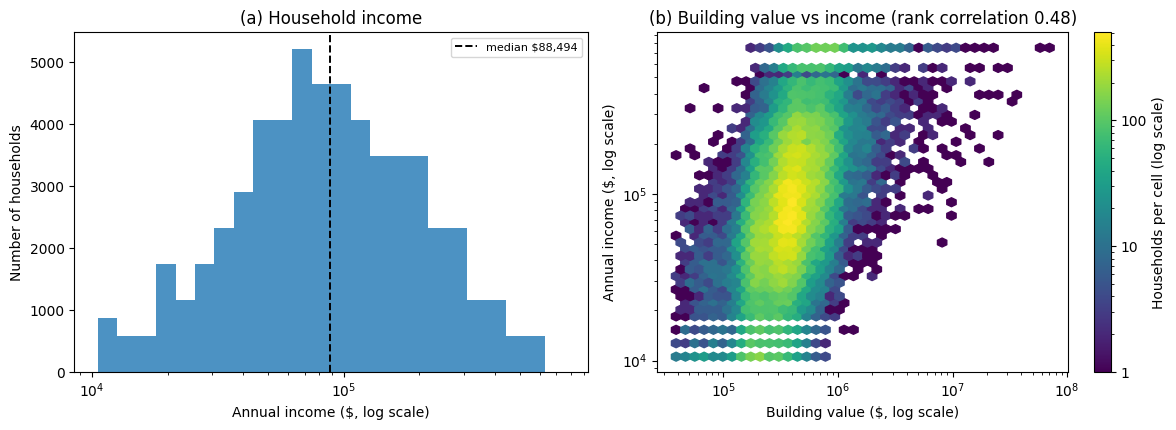

,building value ($),income ($/yr),wealth ($),expected flood damage in 2020 ($/yr)
income percentile,,,,
10,"747,719","28,931","15,333","5,550"
30,"358,129","55,318","143,827",0
50,"318,457","86,793","361,493",0
70,"408,701","139,683","658,605",0
90,"563,609","273,896","1,539,296",0


In [2]:
# Step 1: the regional income curve (ACS 2020-2024, Charleston County).
config.decision.median_income = 88_494.0
config.decision.mean_median_inc_ratio = 131_674.0 / 88_494.0

# Step 2: an income percentile per household, loosely linked to building value.
res_mask = np.char.find(np.asarray(ds["object_id"].attrs["primary_object_type"], dtype=str), "RES") >= 0
building_value = np.asarray(ds["object_id"].attrs["max_pot_dmg"], dtype=float)[res_mask]
income_percentiles = percentiles_from_value_proxy(building_value, rank_correlation=0.5, seed=SEED)

# Step 3 happens inside the engine: income from the curve, wealth from income.
engine = SimulationEngine(ds=ds, config=config, income_percentile_per_agent=income_percentiles)

fig = plotting.plot_agent_profile(engine.max_pot_dmg, engine.income,
                                  median_income=config.decision.median_income)
plt.show()

# Five example households, one at each income quintile midpoint.
engine.prepare_damages(float(slr_values[0]))
ead_today = engine.expected_annual_damages()
rng = np.random.default_rng(SEED)
rows = []
for pct in (10, 30, 50, 70, 90):
    i = rng.choice(np.flatnonzero(income_percentiles == pct))
    rows.append({
        "income percentile": pct,
        "building value ($)": f"{engine.max_pot_dmg[i]:,.0f}",
        "income ($/yr)": f"{engine.income[i]:,.0f}",
        "wealth ($)": f"{engine.wealth[i]:,.0f}",
        "expected flood damage in 2020 ($/yr)": f"{ead_today[i]:,.0f}",
    })
pd.DataFrame(rows).set_index("income percentile")

**What we see**

Incomes run from about \$10,000 to over \$500,000 a year, centred on the Charleston median. Panel (b) shows the loose link with building value. Richer households tend to live in pricier buildings, but each building value comes with a wide spread of incomes (rank correlation 0.48). The stripes at low incomes are the 99 percentile steps of the income curve.

The example households make two points.

* **The link really is loose.** The household at the 10th income percentile lives in a \$750,000 building.
* **Flood risk is concentrated.** Four of the five households expect no flood damage at all in 2020. This skew is the key to the insurance results later on.

## 3. How a household decides

Every year runs through the same steps for all households at once.

1. **Floods.** Each event in the table happens a random number of times, at its own yearly rate.
2. **Damage.** The table gives each household's damage at this year's sea level, with or without floodproofing.
3. **Risk perception.** A flood makes a household take flood risk more seriously. The jump depends on how bad the flood was, and it fades within a few years (figure below).
4. **Decision.** Households that have not floodproofed yet compare their options.
5. **Bookkeeping.** Floodproofing lasts 75 years, so within this 30-year run it is permanent. Insurance covers one year and is decided again every year.

The two decision models side by side:

| | Uniform rule (Run 1) | Coupled DYNAMO-M (Runs 2 to 7) |
|---|---|---|
| Looks at | this year's damage only | every possible flood, weighted by the household's risk perception |
| Acts when | damage exceeds 30 % of the building value | an option has the highest expected utility over the next 15 years |
| Income and wealth | ignored | part of the utility |
| Cost of floodproofing | ignored | 10 % of the building value, paid off as a 16-year loan at 4 % |
| Affordability | ignored | an option costing 6 % of income or more per year is ruled out |
| Options | floodproof or not | do nothing, floodproof, or (Runs 3 to 7) insure |

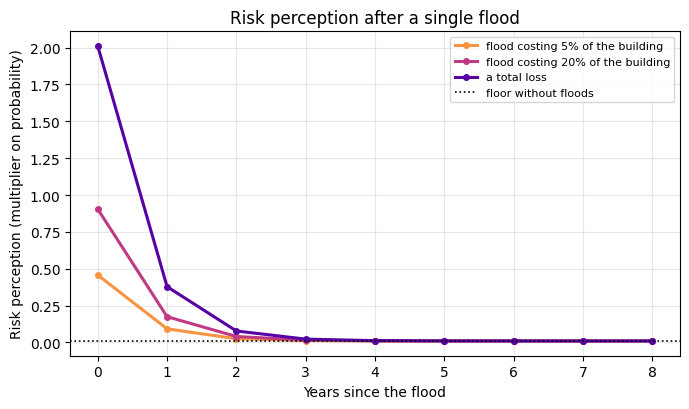

In [3]:
fig = plotting.plot_perception_response(config.decision, severities=(0.05, 0.2, 1.0), years=8)
plt.show()

**What we see**

Without floods, a household weighs flood risk at 1 % of its true probability, so it hardly ever acts. A flood that costs a fifth of the building lifts that weight about ninety-fold. One year later 18 % of the jump is left, after two years only 3 %. Households therefore act in the year or two after a flood, or not at all.

## 4. Runs 1 and 2: a fixed trigger against the coupled model

Both runs face the same floods, so the gap between them is the decision model alone. A third run in which nobody ever adapts gives the reference for avoided damage.

Run 2 uses the preferred setup: the native DYNAMO-M decision code, driven by a DYNAMO-M model clock.

Never adapt          decided by ThresholdRule


1 Uniform rule       decided by ThresholdRule


2 Coupled            decided by DynamoLiveRule


[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)


[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)


...

[calcEU_adapt] Warning, 108382 negative NPVs encountered in floodadapt_abm (0.94%)


[calcEU_do_nothing] Warning, 226708 negative NPVs encountered in floodadapt_abm (1.97%)


[calcEU_adapt] Warning, 115681 negative NPVs encountered in floodadapt_abm (1.0%)


[calcEU_do_nothing] Warning, 239606 negative NPVs encountered in floodadapt_abm (2.08%)


[calcEU_adapt] Warning, 122025 negative NPVs encountered in floodadapt_abm (1.06%)


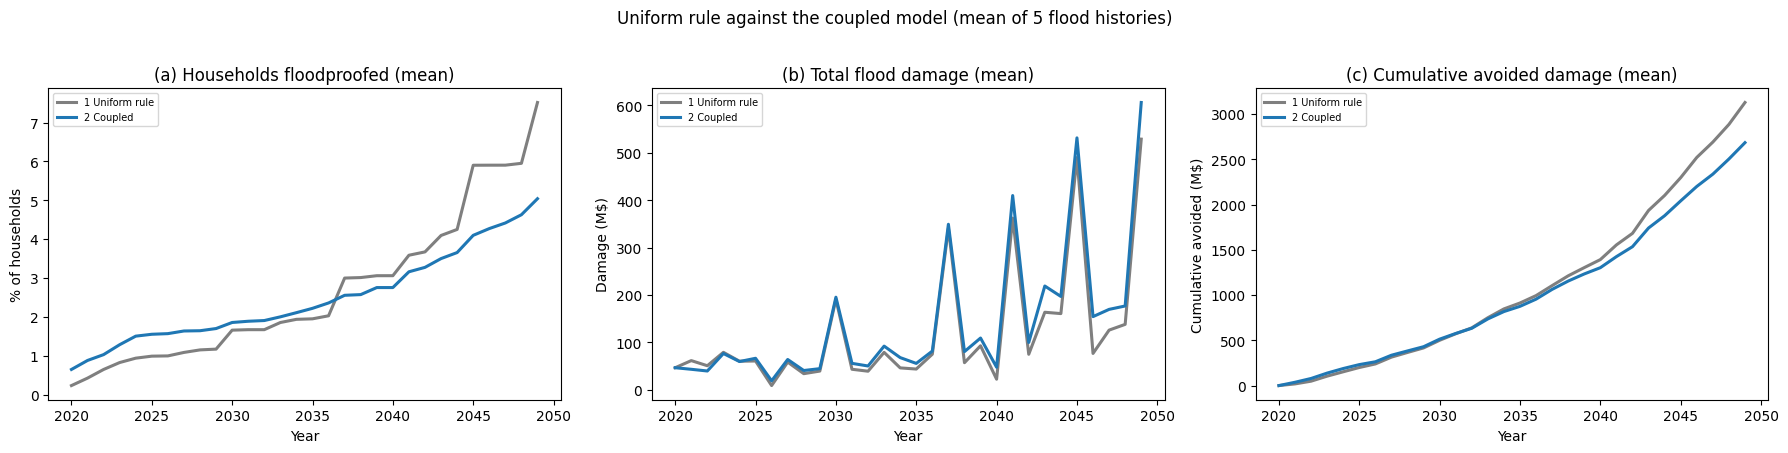

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided (M$)
0,1 Uniform rule,7.52,7.52,3652.9,3128.1
1,2 Coupled,5.04,5.04,4250.8,2684.3


In [4]:
def run_scenario(label, make_rule=preferred_decision_rule, preferred_path=False, **overrides):
    # Run one scenario on the shared flood histories and return its results.
    cfg = CouplingConfig(decision=replace(config.decision, **overrides), random_seed=SEED)
    rule = make_rule(cfg.decision)
    eng = SimulationEngine(ds=ds, config=cfg, decision_rule=rule,
                           income_percentile_per_agent=income_percentiles)
    print(f"{label:<20} decided by {type(rule).__name__}")
    if preferred_path:
        res = run_mesa_native_full(eng, slr_values, no_seq=NO_SEQ, seed=SEED, start_year=START_YEAR)
    else:
        res = eng.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)
    eng.clear_cache()            # free the interpolated damage tables
    return res


never = run_scenario("Never adapt", lambda d: ThresholdRule(d, damage_threshold=1.01),
                     lifespan_dryproof=None)
run1 = run_scenario(RUN1, lambda d: ThresholdRule(d, damage_threshold=0.3))
run2 = run_scenario(RUN2, preferred_path=True)

fig = plotting.plot_rule_hazard_comparison(
    years, {RUN1: run1, RUN2: run2},
    {RUN1: never["damage_history"], RUN2: never["damage_history"]},
    styles=STYLES, title="Uniform rule against the coupled model (mean of 5 flood histories)",
)
plt.show()

analysis.scenario_summary({RUN1: run1, RUN2: run2}, baselines={RUN1: never, RUN2: never})

**What we see**

* **The coupled households act first.** Until the mid-2030s slightly more of them floodproof. They respond to the risk they perceive after a flood, not only to damage already suffered, so a moderate flood can be enough.
* **The uniform rule overtakes later.** From 2037 the large floods push many buildings past the 30 % trigger at once, which shows as steps in panel (a). By 2049, 7.5 % of households have floodproofed under the uniform rule against 5.0 % in the coupled model.
* **Damage follows uptake.** Over 30 years the uniform rule ends with \$598 million less flood damage than the coupled model (\$3,653 million against \$4,251 million).

The gap is the difference between the two decision models by design. The uniform rule floodproofs every badly damaged building, whatever the cost and whoever lives there. Coupled households weigh the cost of the measure, their income, their wealth and a risk perception that fades within two years. The uniform rule is therefore an optimistic, damage-driven benchmark rather than a forecast of behaviour.

## 5. Adding insurance: Runs 3 and 4

Coupled households now have a third option. Insurance pays 90 % of the flood damage for one year. The household keeps the other 10 % (the deductible) and decides again next year. A household that has floodproofed stays floodproofed and does not buy insurance.

The insurer prices the policy in one of two ways.

| Pricing | Premium | Who pays for whom |
|---|---|---|
| Community (Run 3) | the same for everyone: the average expected annual damage of all households | low-risk households subsidise high-risk ones |
| Risk-based (Run 4) | each household's own expected payout, 90 % of its expected annual damage | nobody, the price is actuarially fair |

Run 3 uses the native DYNAMO-M decision code. Run 4 uses the tested Python port of the same code, because native DYNAMO-M can only charge one flat premium.

Both premiums follow the sea level up every year, because expected damage grows with it.

3 Community          decided by DynamoLiveRule


[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)

[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)


[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)


[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)


[calcEU_insure] Warning, 26 negative NPVs encountered in floodadapt_abm (0.0%)


...

[calcEU_do_nothing] Warning, 239606 negative NPVs encountered in floodadapt_abm (2.08%)
[calcEU_do_nothing] Warning, 239606 negative NPVs encountered in floodadapt_abm (2.08%)
[calcEU_do_nothing] Warning, 239606 negative NPVs encountered in floodadapt_abm (2.08%)
[calcEU_do_nothing] Warning, 239606 negative NPVs encountered in floodadapt_abm (2.08%)
[calcEU_do_nothing] Warning, 239606 negative NPVs encountered in floodadapt_abm (2.08%)


[calcEU_adapt] Warning, 122052 negative NPVs encountered in floodadapt_abm (1.06%)


[calcEU_adapt] Warning, 122025 negative NPVs encountered in floodadapt_abm (1.06%)
[calcEU_adapt] Warning, 122057 negative NPVs encountered in floodadapt_abm (1.06%)
[calcEU_adapt] Warning, 122056 negative NPVs encountered in floodadapt_abm (1.06%)
[calcEU_adapt] Warning, 122022 negative NPVs encountered in floodadapt_abm (1.06%)


[calcEU_insure] Warning, 41384 negative NPVs encountered in floodadapt_abm (0.36%)
[calcEU_insure] Warning, 41384 negative NPVs encountered in floodadapt_abm (0.36%)
[calcEU_insure] Warning, 41384 negative NPVs encountered in floodadapt_abm (0.36%)
[calcEU_insure] Warning, 41384 negative NPVs encountered in floodadapt_abm (0.36%)
[calcEU_insure] Warning, 41384 negative NPVs encountered in floodadapt_abm (0.36%)


4 Risk-based         decided by SEURule


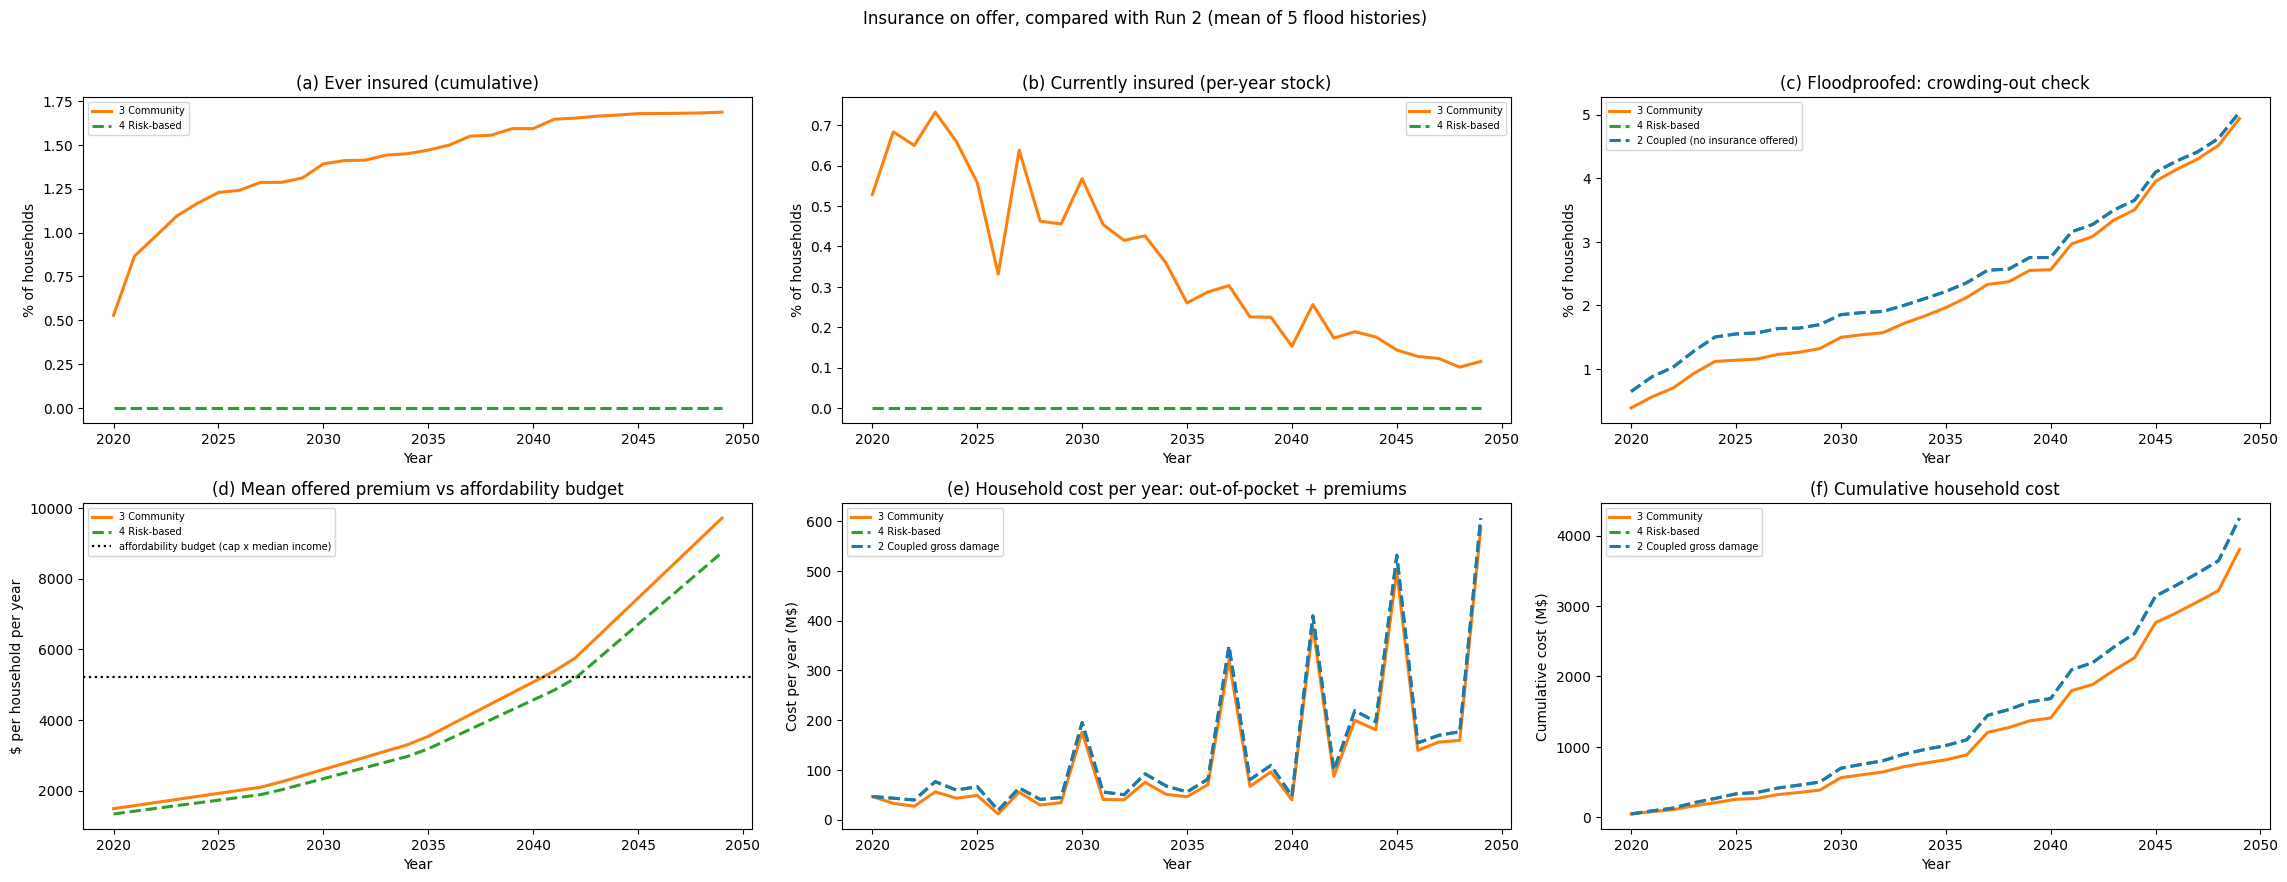

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided vs reference (M$),peak insured (%),final insured (%),ever insured (%),premium final year ($),cum. household cost (M$)
0,2 Coupled,5.04,5.04,4250.8,0.0,NaN,NaN,NaN,NaN,NaN
1,3 Community,4.94,4.94,4769.8,-519.0,0.73,0.12,1.69,9710.0,3806.3
2,4 Risk-based,5.04,5.04,4250.7,0.0,0.00,0.00,0.00,8739.0,4250.7


In [5]:
run3 = run_scenario(RUN3, include_insurance=True, insurance_pricing="community")
run4 = run_scenario(RUN4, include_insurance=True, insurance_pricing="risk_based")

budget = np.median(engine.income) * config.decision.expenditure_cap   # 6 % of median income
fig = plotting.plot_insurance_overview(
    years, {RUN3: run3, RUN4: run4}, reference=run2, cap_budget=budget,
    styles=STYLES, reference_label=RUN2, reference_color=STYLES[RUN2][0],
    title="Insurance on offer, compared with Run 2 (mean of 5 flood histories)",
)
plt.show()

analysis.scenario_summary({RUN2: run2, RUN3: run3, RUN4: run4}, reference=run2)

**What we see**

* **Community pricing sells a little, and less over time.** At most 0.73 % of households hold a policy in any one year (2023). By 2049 only 0.12 % do. Over the whole period 1.69 % insured at least once, more than twice the yearly peak, because households buy for a year or two and then drop out.
* **Risk-based pricing sells nothing.** Not one household buys in any year.
* **Insurance delays floodproofing.** Under community pricing fewer households floodproof in every year (panel c), and total damage over 30 years is \$519 million higher than in Run 2 (\$4,770 million against \$4,251 million). By 2049 the gap in floodproofing has almost closed (4.94 % against 5.04 %). Households insure first and floodproof later, and the years in between are the expensive ones.
* **Households pay less, but someone else pays more.** Out-of-pocket damage plus premiums come to \$3,806 million under community pricing, below Run 2's damage. Only high-risk households buy at the average price, so the insurer pays out about \$960 million more than it collects. The model does not track who covers that shortfall.

### Why so few households buy

The table below looks at the final year, when the risk is highest. It asks two questions for each pricing rule: can a household afford the premium, and does it have any risk worth insuring?

In [6]:
engine.prepare_damages(float(slr_values[-1]))
ead = engine.expected_annual_damages()
cap, deductible = config.decision.expenditure_cap, config.decision.insurance_deductible

skew = analysis.ead_summary(ead)
print(f"Expected annual damage in {years[-1]}: mean ${skew['mean']:,.0f}, median ${skew['median']:,.0f}, "
      f"top 1 % above ${skew['p99']:,.0f}")
print(f"Households with nothing to insure: {100 * skew['share_zero']:.0f} %")
print(f"6 % of median income: ${np.median(engine.income) * cap:,.0f}")

analysis.affordability_table(ead, engine.income, cap, deductible).round(1).set_index("pricing")

Expected annual damage in 2049: mean $9,710, median $136, top 1 % above $187,331
Households with nothing to insure: 38 %
6 % of median income: $5,208


,median premium ($/yr),affordable - all households (%),affordable - top-10% risk (%)
pricing,,,
community (flat),9710.1,25.5,26.1
risk-based,122.1,83.5,4.8


Two numbers explain almost everything. In 2049 the average household expects \$9,710 of flood damage a year, but the median household expects only \$136, and 38 % expect nothing at all. The affordability limit for the median household is \$5,208 a year.

* **Community pricing** charges everyone the average, \$9,710. Three quarters of households cannot afford it. For the median household it is also about 70 times its own risk. Only high-risk households, for whom the average price is a bargain, have a reason to buy. They are Run 3's small uptake, and the rising premium prices more of them out each year.
* **Risk-based pricing** charges each household its own risk. Most households can afford that (83.5 %), but they have little or nothing to insure. Of the riskiest tenth, who need cover most, only 4.8 % can afford it.
* **The result is a pincer.** The households who would buy cannot afford cover, and the households who can afford it do not need it.

This is also why the *currently insured* line falls while the *ever insured* line keeps rising. Insurance is decided again every year with no carry-over. A household buys after a flood, while the fear is fresh, and drops the policy once the fear fades or the rising premium breaches its budget. Floodproofing is bought once and stays.

## 6. Does a subsidy help? Runs 5 to 7

A subsidy pays part of the premium from public money. The insurer still sets the price first, so the risk signal in a risk-based premium survives. This is the design the affordability literature recommends (Kousky and Kunreuther 2014).

* **60 %** is not a round number. The US flood insurance programme ran an implicit subsidy of this size for decades: subsidised policies paid 35 to 40 % of the full-risk rate (GAO-13-607).
* **90 %** is a deliberately deep probe, to find where risk-based pricing starts to work.

First, how deep must a subsidy be before the high-risk households can afford cover at all?

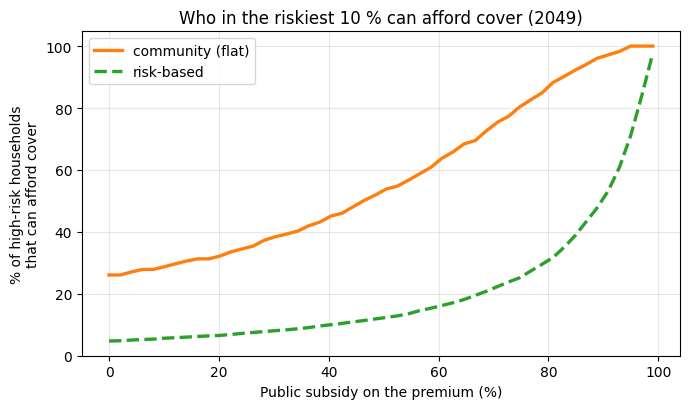

In [7]:
subsidies = np.linspace(0, 0.99, 50)
shares = analysis.affordability_vs_subsidy(ead, engine.income, cap, deductible, subsidies)
fig = plotting.plot_affordability_curve(
    subsidies, shares,
    styles={"community (flat)": STYLES[RUN3], "risk-based": STYLES[RUN4]},
    title=f"Who in the riskiest 10 % can afford cover ({years[-1]})",
)
plt.show()

5 Community + 60%    decided by DynamoLiveRule


[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)

[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)


[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)


[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)


[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)


...

[calcEU_adapt] Warning, 122172 negative NPVs encountered in floodadapt_abm (1.06%)
[calcEU_adapt] Warning, 122174 negative NPVs encountered in floodadapt_abm (1.06%)
[calcEU_adapt] Warning, 122161 negative NPVs encountered in floodadapt_abm (1.06%)
[calcEU_adapt] Warning, 122158 negative NPVs encountered in floodadapt_abm (1.06%)


[calcEU_adapt] Warning, 122154 negative NPVs encountered in floodadapt_abm (1.06%)


[calcEU_insure] Warning, 4846 negative NPVs encountered in floodadapt_abm (0.04%)
[calcEU_insure] Warning, 4846 negative NPVs encountered in floodadapt_abm (0.04%)
[calcEU_insure] Warning, 4846 negative NPVs encountered in floodadapt_abm (0.04%)
[calcEU_insure] Warning, 4846 negative NPVs encountered in floodadapt_abm (0.04%)
[calcEU_insure] Warning, 4846 negative NPVs encountered in floodadapt_abm (0.04%)


6 Risk-based + 60%   decided by SEURule


7 Risk-based + 90%   decided by SEURule


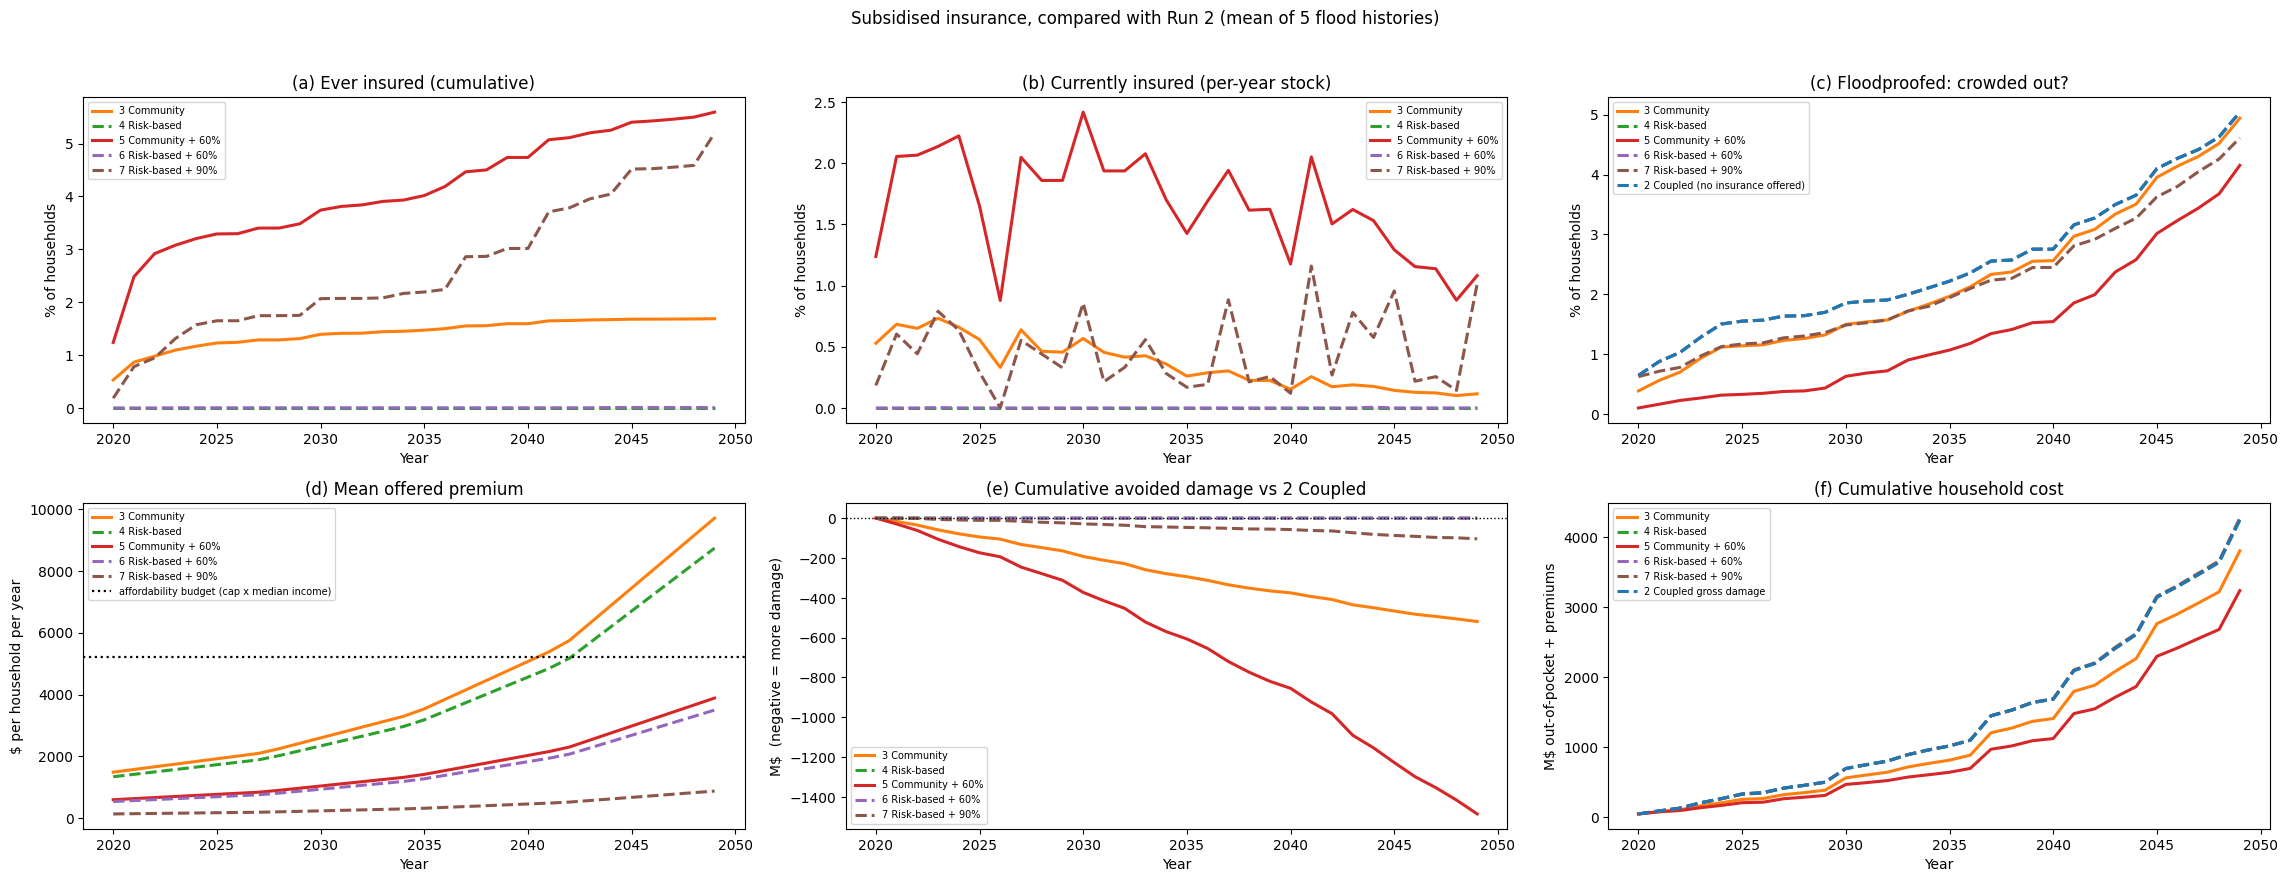

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided vs reference (M$),peak insured (%),final insured (%),ever insured (%),premium final year ($),cum. household cost (M$)
0,3 Community,4.94,4.94,4769.8,-519.0,0.73,0.12,1.69,9710.0,3806.3
1,4 Risk-based,5.04,5.04,4250.7,0.0,0.00,0.00,0.00,8739.0,4250.7
2,5 Community + 60%,4.15,4.15,5735.7,-1485.0,2.42,1.08,5.59,3884.0,3238.7
3,6 Risk-based + 60%,5.04,5.04,4250.7,0.0,0.01,0.00,0.01,3496.0,4250.7
4,7 Risk-based + 90%,4.61,4.61,4354.7,-104.0,1.16,1.02,5.20,874.0,4274.5


In [8]:
run5 = run_scenario(RUN5, include_insurance=True, insurance_pricing="community", insurance_subsidy=0.6)
run6 = run_scenario(RUN6, include_insurance=True, insurance_pricing="risk_based", insurance_subsidy=0.6)
run7 = run_scenario(RUN7, include_insurance=True, insurance_pricing="risk_based", insurance_subsidy=0.9)

insurance_runs = {RUN3: run3, RUN4: run4, RUN5: run5, RUN6: run6, RUN7: run7}
fig = plotting.plot_subsidy_experiment(
    years, insurance_runs, reference=run2, styles=STYLES, cap_budget=budget,
    reference_label=RUN2, reference_color=STYLES[RUN2][0],
    title="Subsidised insurance, compared with Run 2 (mean of 5 flood histories)",
)
plt.show()

analysis.scenario_summary(insurance_runs, reference=run2)

**What we see**

**Affordability first (the curve).** Without a subsidy, 26 % of the riskiest tenth can afford the community premium and 5 % the risk-based one. At 60 % subsidy that becomes 63 % and 16 %. Risk-based cover only reaches half of these households at 90 %. The subsidy takes a share off the premium, but the 6 % limit is a fixed amount, so the largest premiums stay out of reach.

**What the runs show.**

* **Risk-based + 60 % (Run 6) changes nothing.** Almost nobody buys (0.01 %), and the results are identical to Run 2.
* **Risk-based + 90 % (Run 7) finally sells.** At most 1.2 % hold a policy in any one year, but 5.2 % insure at some point. Floodproofing falls from 5.04 % to 4.61 %, and total damage rises by \$104 million.
* **Community + 60 % (Run 5) sells most.** Up to 2.4 % hold a policy in a year and 5.6 % insure at some point. Floodproofing falls to 4.15 %, and total damage rises by \$1,485 million, 35 % more than Run 2.
* **Affordable is not the same as attractive.** Far more households could afford cover than actually buy it. Insuring must also beat floodproofing and doing nothing in the household's own calculation.

**A worked example: why 60 % changes nothing for risk-based pricing but 90 % raises damage.** In Run 6 nobody buys. The decision rules never touch the flood draws, so Run 6 sees Run 2's floods and makes Run 2's floodproofing decisions, which gives exactly the same damage. In Run 7 some high-risk households now clear the affordability limit and insure *instead of* floodproofing. Insurance pays for the damage but does not prevent it, so total damage goes up.

**The reading.** Risk-based pricing only moves at around 90 % subsidy. Community pricing moves earlier because its flat rate already sits close to many households' budgets. In every run, each gain in uptake is paid for in floodproofing, so a uniform subsidy sells insurance at the expense of protection. Support aimed at each household's affordability gap and tied to floodproofing would avoid that (Kousky and Kunreuther 2014).

## 7. Summary

All seven runs in one table. Avoided damage is measured twice: against the households never adapting, and against Run 2 (negative means more damage than Run 2).

In [9]:
all_runs = {RUN1: run1, RUN2: run2, **insurance_runs}
analysis.scenario_summary(all_runs, reference=run2, baselines={k: never for k in all_runs})

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided (M$),cum. avoided vs reference (M$),peak insured (%),final insured (%),ever insured (%),premium final year ($),cum. household cost (M$)
0,1 Uniform rule,7.52,7.52,3652.9,3128.1,597.9,NaN,NaN,NaN,NaN,NaN
1,2 Coupled,5.04,5.04,4250.8,2684.3,0.0,NaN,NaN,NaN,NaN,NaN
2,3 Community,4.94,4.94,4769.8,2199.5,-519.0,0.73,0.12,1.69,9710.0,3806.3
3,4 Risk-based,5.04,5.04,4250.7,2684.4,0.0,0.00,0.00,0.00,8739.0,4250.7
4,5 Community + 60%,4.15,4.15,5735.7,1281.5,-1485.0,2.42,1.08,5.59,3884.0,3238.7
5,6 Risk-based + 60%,5.04,5.04,4250.7,2684.4,0.0,0.01,0.00,0.01,3496.0,4250.7
6,7 Risk-based + 90%,4.61,4.61,4354.7,2580.4,-104.0,1.16,1.02,5.20,874.0,4274.5


**Takeaways**

1. **The decision model matters.** With identical floods, the uniform rule floodproofs 7.5 % of households and the coupled model 5.0 %. Coupled households act earlier but fewer act overall, because they weigh cost, income and a fading risk perception.
2. **Flood risk is concentrated.** In 2049 the median household expects \$136 of damage a year, the average household \$9,710.
3. **Voluntary insurance barely sells, under either pricing rule, for opposite reasons.** Community pricing is too expensive for most and a bargain only for the high-risk few. Risk-based pricing is affordable only for those with little to insure.
4. **Subsidised insurance sells more but raises total damage.** Insurance moves losses around and does not prevent them, so every policy bought instead of floodproofing adds damage. Run 5 adds \$1,485 million, 35 % more than Run 2.

**Questions for discussion**

* Is a 30 % damage trigger a fair benchmark for a simple rule, or should it be calibrated?
* Is 6 % of income the right affordability limit for Charleston households?
* Should insurance cover be conditional on floodproofing, or the subsidy means-tested?
* Should the insurer's balance be modelled, since community pricing runs a deficit?

**Where next**

* [3_coupled_abm_full_analysis.ipynb](3_coupled_abm_full_analysis.ipynb): every scenario, including the clipped flood draw, the income methods for other data situations, and the verification checks.
* [docs/architecture.md](../docs/architecture.md): the model description in ODD form, the insurance pricing rationale with references (section 9.7) and every deviation from native DYNAMO-M (Appendix B).
* [docs/calibration_validation_guide.md](../docs/calibration_validation_guide.md): which parameters matter most and what data would calibrate them.